In [1]:
# =====================================
# CNN1D FULLY SEGMENT EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_fully_hmm_cnn_mamba_classifier import RunFullyHmmCnnMambaClassifier
from src.run.preprocess.config import _project_path


=== Running experiment with tol=0.01 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
[Fold 01] Epoch 001 | Train loss: 1.0142 | Train acc: 0.5167 | Val loss: 1.0360 | Val acc: 0.4667 | auc: 0.8571
[Fold 01] Epoch 002 | Train loss: 0.6471 | Train acc: 0.6167 | Val loss: 0.5828 | Val acc: 0.7333 | auc: 0.8393
[Fold 01] Epoch 003 | Train loss: 0.6412 | Train acc: 0.6500 | Val loss: 0.5606 | Val acc: 0.6667 | auc: 0.8571
[Fold 01] Epoch 004 | Train loss: 0.6115 | Train acc: 0.7333 | Val loss: 0.5477 | Val acc: 0.7333 | auc: 0.8393
[Fold 01] Epoch 005 | Train loss: 0.6046 | Train acc: 0.7333 | Val loss: 0.5248 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 006 | Train loss: 0.5986 | Train acc: 0.7333 | Val loss: 0.4839 | Val acc: 0.8000 | auc: 0.

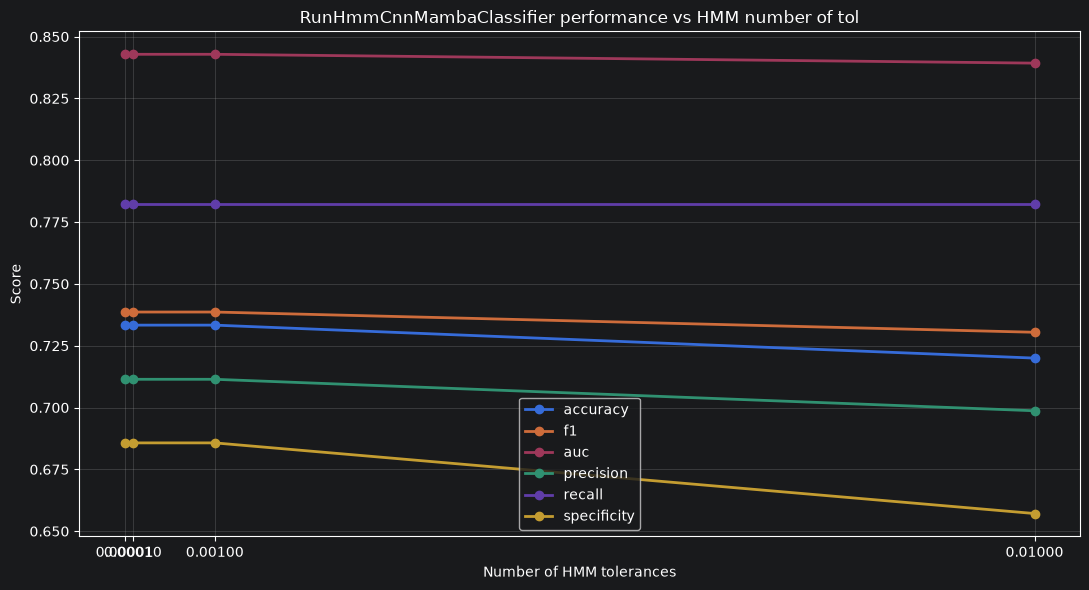


=== BEST HMM TOL ===
tol: 0
Accuracy: 0.7333
F1: 0.7386
AUC: 0.8429
Precision: 0.7114
Recall: 0.7821
Specificity: 0.6857


In [2]:
# HMM TOL

tols = [1e-2, 1e-3, 1e-4, 1e-5]

results = []

for t in tols:

    print(
        f"\n=== Running experiment with tol={t} ==="
    )

    runner = RunFullyHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=100,
        tol=t,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val seg)/"
            f"hmm_tol/tol_{t}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "tol": t,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "tol"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_mamba_tol_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["tol"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["tol"]
)

plt.xlabel("Number of HMM tolerances")
plt.ylabel(metric)
plt.legend()
plt.tight_layout()

plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier performance vs HMM number of tol"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST HMM TOL ===")

print(
    f"tol: {int(best['tol'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with n_iter=50 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
[Fold 01] Epoch 001 | Train loss: 1.0142 | Train acc: 0.5167 | Val loss: 1.0360 | Val acc: 0.4667 | auc: 0.8571
[Fold 01] Epoch 002 | Train loss: 0.6471 | Train acc: 0.6167 | Val loss: 0.5828 | Val acc: 0.7333 | auc: 0.8393
[Fold 01] Epoch 003 | Train loss: 0.6412 | Train acc: 0.6500 | Val loss: 0.5606 | Val acc: 0.6667 | auc: 0.8571
[Fold 01] Epoch 004 | Train loss: 0.6115 | Train acc: 0.7333 | Val loss: 0.5477 | Val acc: 0.7333 | auc: 0.8393
[Fold 01] Epoch 005 | Train loss: 0.6046 | Train acc: 0.7333 | Val loss: 0.5248 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 006 | Train loss: 0.5986 | Train acc: 0.7333 | Val loss: 0.4839 | Val acc: 0.8000 | auc: 0

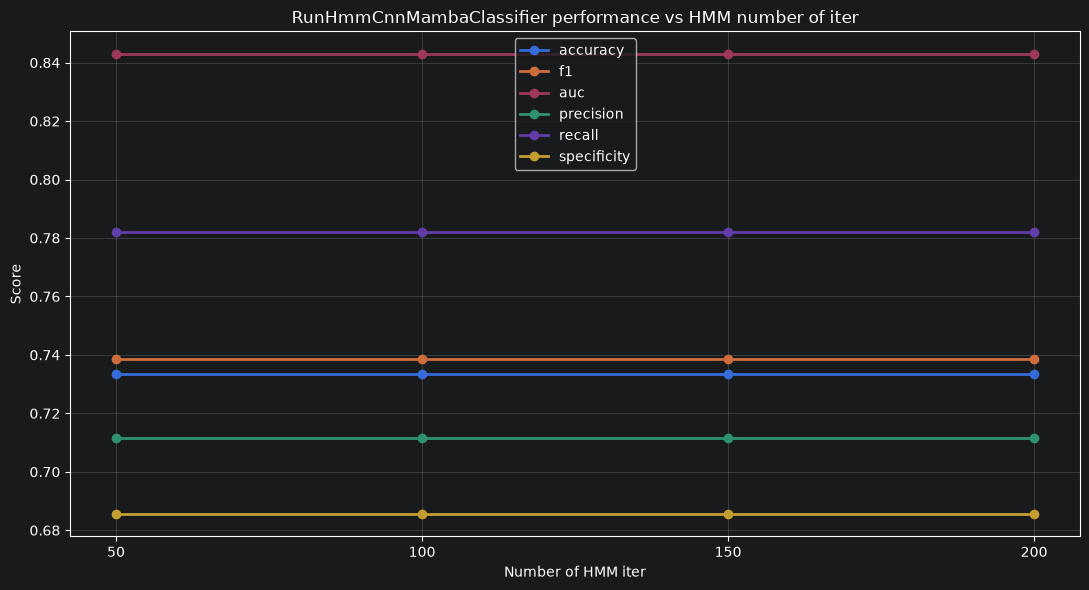


=== BEST HMM N_ITER ===
n_iter: 50
Accuracy: 0.7333
F1: 0.7386
AUC: 0.8429
Precision: 0.7114
Recall: 0.7821
Specificity: 0.6857


In [3]:
# HMM N_ITER

n_iter = [50, 100, 150, 200]

results = []

for i in n_iter:

    print(
        f"\n=== Running experiment with n_iter={i} ==="
    )

    runner = RunFullyHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=i,
        tol=1e-3,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val seg)/"
            f"hmm_n_iter/iter_{i}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "n_iter": i,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "n_iter"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_hmm_cnn_mamba_n_iter_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["n_iter"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["n_iter"]
)

plt.xlabel("Number of HMM iter")

plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier performance vs HMM number of iter"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST HMM N_ITER ===")

print(
    f"n_iter: {int(best['n_iter'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with epoch=50 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
[Fold 01] Epoch 001 | Train loss: 1.0142 | Train acc: 0.5167 | Val loss: 1.0360 | Val acc: 0.4667 | auc: 0.8571
[Fold 01] Epoch 002 | Train loss: 0.6471 | Train acc: 0.6167 | Val loss: 0.5828 | Val acc: 0.7333 | auc: 0.8393
[Fold 01] Epoch 003 | Train loss: 0.6412 | Train acc: 0.6500 | Val loss: 0.5606 | Val acc: 0.6667 | auc: 0.8571
[Fold 01] Epoch 004 | Train loss: 0.6115 | Train acc: 0.7333 | Val loss: 0.5477 | Val acc: 0.7333 | auc: 0.8393
[Fold 01] Epoch 005 | Train loss: 0.6046 | Train acc: 0.7333 | Val loss: 0.5248 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 006 | Train loss: 0.5986 | Train acc: 0.7333 | Val loss: 0.4839 | Val acc: 0.8000 | auc: 0.

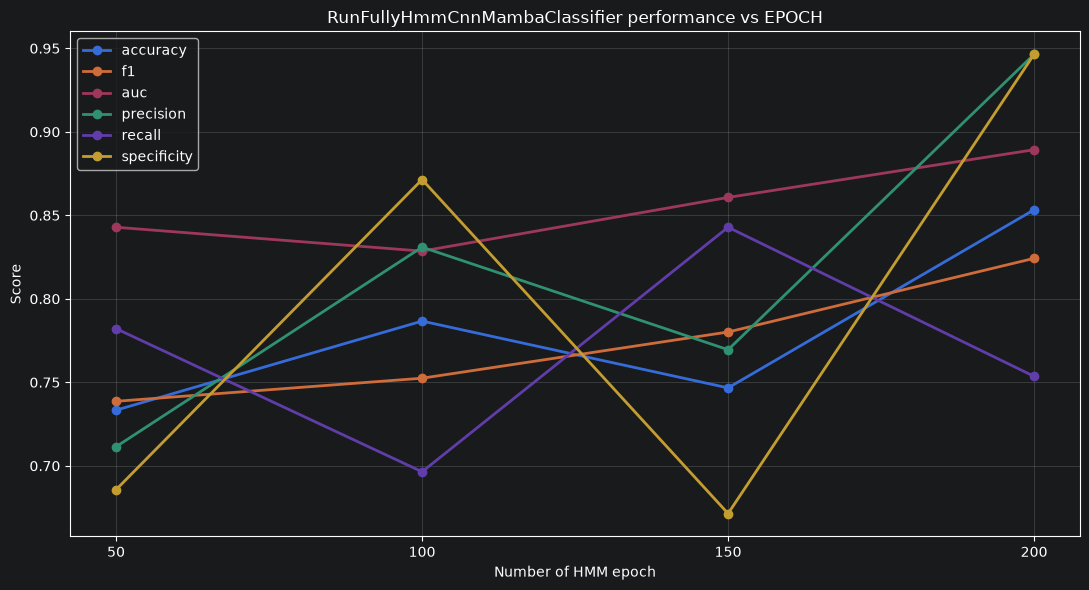


=== BEST EPOCH ===
epoch: 200
Accuracy: 0.8533
F1: 0.8242
AUC: 0.8893
Precision: 0.9464
Recall: 0.7536
Specificity: 0.9464


In [4]:
# HMM EPOCHS

epochs = [50, 100, 150, 200]

results = []

for e in epochs:

    print(
        f"\n=== Running experiment with epoch={e} ==="
    )

    runner = RunFullyHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=e,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-3,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val seg)/"
            f"epochs/e_{e}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "epoch": e,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "epoch"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_hmm_cnn_mamba_epoch_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["epoch"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["epoch"]
)

plt.xlabel("Number of HMM epoch")
plt.ylabel(metric)
plt.legend()
plt.tight_layout()

plt.ylabel("Score")

plt.title(
    "RunFullyHmmCnnMambaClassifier performance vs EPOCH"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST EPOCH ===")

print(
    f"epoch: {int(best['epoch'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)

In [8]:
# HMM LEARNING RATE SWEEP

learning_rates = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 2e-3, 2e-4]

results = []

for lr in learning_rates:

    print(
        f"\n=== Running experiment with learning_rate={lr:.0e} ==="
    )

    runner = RunFullyHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=200,

        batch_size=16,

        learning_rate=lr,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-2,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val seg)/"
            f"learning_rate/lr_{lr:.0e}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "learning_rate": lr,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "learning_rate"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_hmm_cnn_mamba_lr_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["learning_rate"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xticks(
    df["learning_rate"],
    [f"{lr:.0e}" for lr in df["learning_rate"]]
)

plt.xlabel("Learning rate (log scale)")
plt.ylabel("Score")

plt.title(
    f"RunFullyHmmCnnMambaClassifier performance vs LEARNING RATE "
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST LEARNING RATE ===")

print(
    f"learning_rate: {best['learning_rate']:.0e}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with learning_rate=1e-06 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
[Fold 01] Epoch 001 | Train loss: 0.8213 | Train acc: 0.4833 | Val loss: 0.7583 | Val acc: 0.5333 | auc: 0.6607
[Fold 01] Epoch 002 | Train loss: 0.8168 | Train acc: 0.4833 | Val loss: 0.7547 | Val acc: 0.5333 | auc: 0.6429
[Fold 01] Epoch 003 | Train loss: 0.8123 | Train acc: 0.4833 | Val loss: 0.7510 | Val acc: 0.5333 | auc: 0.6429


KeyboardInterrupt: 


=== Running experiment with regularization=1e-08 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
[Fold 01] Epoch 001 | Train loss: 0.6624 | Train acc: 0.6167 | Val loss: 0.6166 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 002 | Train loss: 0.6789 | Train acc: 0.5167 | Val loss: 0.6568 | Val acc: 0.5333 | auc: 0.8571
[Fold 01] Epoch 003 | Train loss: 0.6399 | Train acc: 0.6500 | Val loss: 0.5909 | Val acc: 0.8000 | auc: 0.8750
[Fold 01] Epoch 004 | Train loss: 0.6017 | Train acc: 0.7333 | Val loss: 0.5182 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 005 | Train loss: 0.6028 | Train acc: 0.7167 | Val loss: 0.4977 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 006 | Train loss: 0.5966 | Train acc: 0.7333 | Val loss: 0.4884 | Val acc: 0.80

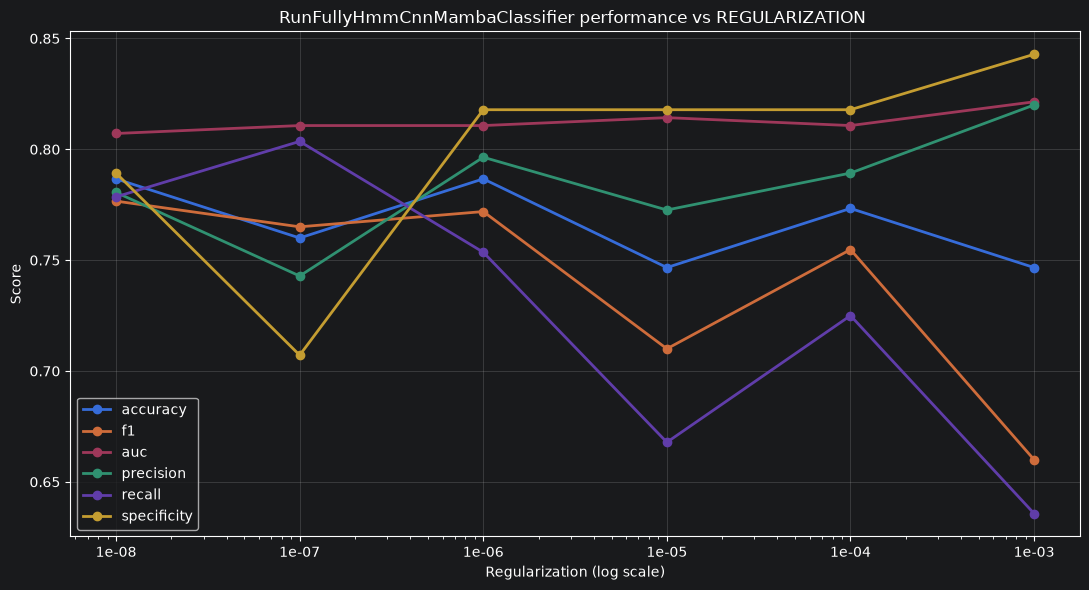


=== BEST REGULARIZATION ===
regularization: 1e-03
Accuracy: 0.7467
F1: 0.6600
AUC: 0.8214
Precision: 0.8200
Recall: 0.6357
Specificity: 0.8429


In [2]:
# FULLY HMM REGULARIZATION SWEEP

regs = [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3]

results = []

for reg in regs:

    print(
        f"\n=== Running experiment with regularization={reg:.0e} ==="
    )

    runner = RunFullyHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=200,

        batch_size=16,

        learning_rate=1e-4,

        regularization=reg,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-2,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val seg)/"
            f"regularization/reg_{reg:.0e}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "regularization": reg,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "regularization"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_hmm_cnn_mamba_regularization_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["regularization"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xticks(
    df["regularization"],
    [f"{r:.0e}" for r in df["regularization"]]
)

plt.xlabel("Regularization (log scale)")
plt.ylabel("Score")

plt.title(
    f"RunFullyHmmCnnMambaClassifier performance vs REGULARIZATION "
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST REGULARIZATION ===")

print(
    f"regularization: {best['regularization']:.0e}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
[Fold 01] Epoch 001 | Train loss: 0.6624 | Train acc: 0.6167 | Val loss: 0.6166 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 002 | Train loss: 0.6789 | Train acc: 0.5167 | Val loss: 0.6568 | Val acc: 0.5333 | auc: 0.8571
[Fold 01] Epoch 003 | Train loss: 0.6399 | Train acc: 0.6500 | Val loss: 0.5909 | Val acc: 0.8000 | auc: 0.8750
[Fold 01] Epoch 004 | Train loss: 0.6017 | Train acc: 0.7333 | Val loss: 0.5182 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 005 | Train loss: 0.6028 | Train acc: 0.7167 | Val loss: 0.4977 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 006 | Train loss: 0.5966 | Train acc: 0.7333 | Val loss: 0.4884 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 007 | Train loss: 0.5

C:\Users\Utente\AppData\Local\Temp\ipykernel_4144\2436567724.py:145: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Utente\parkinson_disease\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


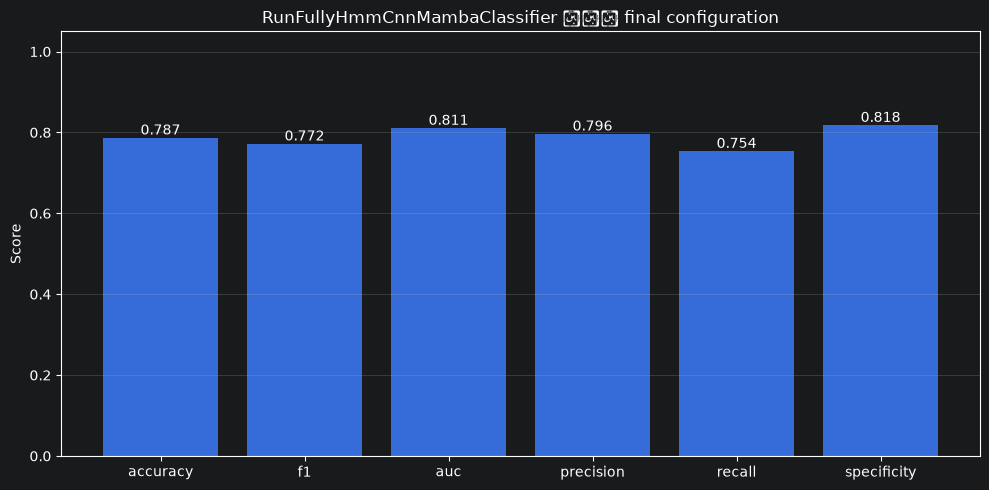


=== FINAL CONFIGURATION ===
Accuracy: 0.7867
F1: 0.7719
Auc: 0.8107
Precision: 0.7964
Recall: 0.7536
Specificity: 0.8179


In [3]:
# RUN FULLY HMM CNN MAMBA CLASSIFIER

runner = RunFullyHmmCnnMambaClassifier(
    data_root=_project_path(
        "PaHaW/PaHaW/PaHaW_public"
    ),

    metadata_path=_project_path(
        "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
    ),

    # =====================================================
    # Configurazione dati
    # =====================================================

    tasks=[1, 8],

    feature_names=("x", "y"),

    engineered_features=(
        "pressure_derivative",
    ),

    # =====================================================
    # Training
    # =====================================================

    epochs=200,

    batch_size=16,

    learning_rate=1e-4,

    regularization=1e-6,

    # =====================================================
    # HMM
    # =====================================================

    n_states=2,
    covariance_type="diag",
    n_iter=50,
    tol=1e-2,
    random_state=42,
    algorithm="viterbi",
    verbose=False,

    n_splits=5,

    normalize=True,

    device=(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    ),

    output_dir=_project_path(
        "experiments/cnn1D + mamba/"
        "hmm(train seg - val seg)/task_1_8/xy_pressure_derivative"
    ),

    training_cfg={
        "metrics": [
            "accuracy",
            "f1",
            "auc",
            "precision",
            "recall",
            "specificity",
        ],

        "monitor_metric": "auc",

        "early_stopping_patience": float("inf"),

        "min_delta": 0.0,

        "normalize": True,

        "normalization_eps": 1e-6,

        "results_writer": "csv",

        "save_metrics": True,
    },
)

summary = runner.run()


# =========================================================
# RISULTATI
# =========================================================

df = pd.DataFrame([summary["averages"]])

print("\n=== Summary ===")
print(df.T)

df.to_csv(
    "fully_hmm_cnn_mamba_final_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

labels = [m.replace("val_", "") for m in metrics]
values = [summary["averages"][m] for m in metrics]

plt.figure(figsize=(10, 5))

bars = plt.bar(labels, values)

plt.bar_label(
    bars,
    fmt="%.3f"
)

plt.ylim(0, 1.05)
plt.ylabel("Score")

plt.title(
    "RunFullyHmmCnnMambaClassifier - final configuration"
)

plt.grid(
    True,
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# =========================================================
# FINAL METRICS
# =========================================================

print("\n=== FINAL CONFIGURATION ===")

for m, label in zip(metrics, labels):
    print(f"{label.capitalize()}: {summary['averages'][m]:.4f}")

In [5]:
# =====================================
# Dipendenze
# =====================================
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# =====================================
# 1. Esegui l'esperimento
# =====================================
runner = RunFullyHmmCnnMambaClassifier(
    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
    tasks=[1, 8],
    feature_names=("x", "y"),
    engineered_features=("pressure_derivative",),
    epochs=200,
    batch_size=16,
    learning_rate=1e-4,
    regularization=1e-6,
    n_states=2,
    covariance_type="diag",
    n_iter=50,
    tol=1e-2,
    random_state=42,
    algorithm="viterbi",
    verbose=False,
    n_splits=5,
    normalize=True,
    device=("cuda" if torch.cuda.is_available() else "cpu"),
    output_dir=_project_path("experiments/cnn1D + mamba/hmm(train seg - val seg)/task_1_8/xy_pressure_derivative"),
    training_cfg={
        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
        "monitor_metric": "auc",
        "early_stopping_patience": float("inf"),
        "min_delta": 0.0,
        "normalize": True,
        "normalization_eps": 1e-6,
        "results_writer": "csv",
        "save_metrics": True,
    },
)
summary = runner.run()

# =====================================
# 2. Risultati (ultima epoca)
# =====================================
averages = summary["averages"]

print("\n=== FINAL RESULTS (Last Epoch) ===")
print(f"Accuracy:    {averages['last_val_accuracy']:.4f}")
print(f"F1 Score:    {averages['last_val_f1']:.4f}")
print(f"AUC:         {averages['last_val_auc']:.4f}")
print(f"Precision:   {averages['last_val_precision']:.4f}")
print(f"Recall:      {averages['last_val_recall']:.4f}")
print(f"Specificity: {averages['last_val_specificity']:.4f}")

metrics = ["accuracy", "f1", "auc", "precision", "recall", "specificity"]
values = [averages[f"last_val_{m}"] for m in metrics]

plt.figure(figsize=(10, 5))
bars = plt.bar(metrics, values)
plt.bar_label(bars, fmt="%.3f")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("RunFullyHmmCnnMambaClassifier - Results (Last Epoch)")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================
# 3. Grad-CAM sulla CNN encoder, rispetto al logit finale del paziente
# =====================================
FOLD = 1
SEG_IDX = 0              # segmento da visualizzare nel plot dettagliato
TARGET = "label"         # "label" = classe vera, "pred" = classe predetta dal modello

if not hasattr(runner, "trained_models_") or FOLD not in runner.trained_models_:
    raise AttributeError(
        "Il runner non ha salvato i modelli. Assicurati di aver modificato "
        "la classe RunFullyHmmCnnMambaClassifier e di aver riavviato il kernel."
    )

model = runner.trained_models_[FOLD]
model.eval()
model.to(runner.device)
segment_encoder = model.segment_encoder

val_ds_raw = runner.val_datasets_[FOLD]
norm_payload = runner.normalization_payloads_[FOLD]

sample = val_ds_raw[0]
segments_raw = sample["segments"].float()         # [S, T, F]
segment_masks = sample["segment_masks"].bool()    # [S, T]
patient_label = int(sample["label"])
patient_id = sample["patient_id"]

# Normalizzazione manuale (come nel runner)
mean = torch.tensor(norm_payload["mean"], dtype=torch.float32)
std = torch.tensor(norm_payload["std"], dtype=torch.float32).clamp_min(runner.normalization_eps)
segments = (segments_raw - mean) / std
segments = segments * segment_masks.unsqueeze(-1)

S, T, F_dim = segments.shape
sequence_mask = segment_masks.any(dim=-1)         # [S] segmenti reali

print(f"\n[Grad-CAM] patient={patient_id}, label={patient_label}, "
      f"n_segments={S}, valid_segments={int(sequence_mask.sum())}, T={T}")

# Ultimo Conv1d della CNN
conv_names = [n for n, m in segment_encoder.named_modules() if isinstance(m, nn.Conv1d)]
print("Conv1d nel segment_encoder:", conv_names)
target_layer = conv_names[-1]
target_module = segment_encoder.get_submodule(target_layer)

# Hook: il modello chiama la CNN una volta per ogni gruppo di segmenti con la stessa
# lunghezza reale, quindi registriamo ogni chiamata separatamente.
calls = []

def fwd_hook(module, inp, out):
    rec = {"acts": out}
    calls.append(rec)
    out.register_hook(lambda g, rec=rec: rec.__setitem__("grads", g))

handle = target_module.register_forward_hook(fwd_hook)

x = segments.unsqueeze(0).to(runner.device)                  # [1, S, T, F]
sm = segment_masks.unsqueeze(0).to(runner.device)            # [1, S, T]
qm = sequence_mask.unsqueeze(0).to(runner.device)            # [1, S]

model.eval()
model.zero_grad()
with torch.enable_grad():
    logits = model(x, sm, qm)                                # [1, num_classes]
    probs = torch.softmax(logits, dim=-1)[0].detach().cpu().numpy()
    pred_class = int(logits.argmax(dim=-1))
    target_class = patient_label if TARGET == "label" else pred_class
    logits[0, target_class].backward()

handle.remove()

class_names = ["Healthy", "Parkinson"]
print(f"Probabilità paziente: Healthy={probs[0]:.3f}, Parkinson={probs[1]:.3f} | "
      f"predetto={class_names[pred_class]} | spiegato={class_names[target_class]}")

# Ricostruzione dell'ordine delle chiamate, uguale a quello del forward del modello:
# lunghezze reali uniche in ordine crescente, segmenti in ordine di indice.
real_lengths = segment_masks.sum(dim=-1).long()              # [S]
unique_lengths = torch.unique(real_lengths[sequence_mask])
groups = []
for L in unique_lengths:
    idx = ((real_lengths == L) & sequence_mask).nonzero(as_tuple=False).flatten().tolist()
    groups.append((int(L), idx))

assert len(groups) == len(calls), (
    f"Chiamate alla CNN registrate ({len(calls)}) diverse dai gruppi attesi ({len(groups)})."
)

# CAM per segmento: peso = gradiente medio sul tempo, somma pesata dei canali, ReLU
cams_raw = {}    # seg_idx -> array [L] con valori non normalizzati
for rec, (L, idx) in zip(calls, groups):
    acts = rec["acts"].detach()                               # [N, C, T']
    grads = rec["grads"].detach()                             # [N, C, T']
    weights = grads.mean(dim=2, keepdim=True)
    cam = torch.relu((weights * acts).sum(dim=1)).cpu().numpy()   # [N, T']
    for n, s in enumerate(idx):
        c = cam[n]
        if c.shape[0] != L:
            c = np.interp(np.linspace(0, 1, L), np.linspace(0, 1, c.shape[0]), c)
        cams_raw[s] = c

# Importanza per segmento (scala comune, non normalizzata)
seg_importance = np.array([cams_raw[s].sum() if s in cams_raw else 0.0 for s in range(S)])

# =====================================
# 4. Plot: importanza dei segmenti
# =====================================
plt.figure(figsize=(10, 3.5))
plt.bar(np.arange(S), seg_importance, color=["C3" if s == SEG_IDX else "C0" for s in range(S)])
plt.xlabel("Indice segmento")
plt.ylabel("Importanza (somma CAM)")
plt.title(f"Importanza dei segmenti per la classe '{class_names[target_class]}' — patient {patient_id}")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================
# 5. Plot: segnale + CAM del segmento scelto
# =====================================
segment = segments[SEG_IDX]            # [T, F]
mask_seg = segment_masks[SEG_IDX]      # [T]
L_valid = int(mask_seg.sum())

cam_array = np.zeros(T, dtype=np.float32)
if SEG_IDX in cams_raw:
    cam_array[:L_valid] = cams_raw[SEG_IDX][:L_valid]
cam_array = cam_array - cam_array[:L_valid].min() if L_valid > 0 else cam_array
cam_array[L_valid:] = 0
if cam_array.max() > 0:
    cam_array = cam_array / cam_array.max()

feature_names_plot = list(runner.feature_names) + list(runner.engineered_features)
n_features = segment.shape[1]
t_axis = np.arange(T)

fig, axes = plt.subplots(n_features + 1, 1, figsize=(12, 2.2 * (n_features + 1)), sharex=True)

for i in range(n_features):
    ax = axes[i]
    ax.plot(t_axis, segment[:, i].numpy(), color="C0")
    ax.set_ylabel(feature_names_plot[i])
    ax.grid(True, alpha=0.3)
    if L_valid < T:
        ax.axvspan(L_valid, T, color="gray", alpha=0.15)

axes[0].set_title(
    f"Grad-CAM (CNN encoder di HMM+CNN+Mamba, rispetto al logit del paziente) — "
    f"patient {patient_id}, segment {SEG_IDX}, label={class_names[patient_label]}"
)

ax_cam = axes[-1]
ax_cam.plot(t_axis, cam_array, color="C3", linewidth=1.5)
ax_cam.fill_between(t_axis, 0, cam_array, color="C3", alpha=0.35)
ax_cam.set_ylabel("CAM")
ax_cam.set_xlabel("Timestep nel segmento")
ax_cam.grid(True, alpha=0.3)
if L_valid < T:
    ax_cam.axvspan(L_valid, T, color="gray", alpha=0.15)

plt.tight_layout()
plt.show()


START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
[Fold 01] Epoch 001 | Train loss: 0.6624 | Train acc: 0.6167 | Val loss: 0.6166 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 002 | Train loss: 0.6789 | Train acc: 0.5167 | Val loss: 0.6568 | Val acc: 0.5333 | auc: 0.8571
[Fold 01] Epoch 003 | Train loss: 0.6399 | Train acc: 0.6500 | Val loss: 0.5909 | Val acc: 0.8000 | auc: 0.8750
[Fold 01] Epoch 004 | Train loss: 0.6017 | Train acc: 0.7333 | Val loss: 0.5182 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 005 | Train loss: 0.6028 | Train acc: 0.7167 | Val loss: 0.4977 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 006 | Train loss: 0.5966 | Train acc: 0.7333 | Val loss: 0.4884 | Val acc: 0.8000 | auc: 0.8393
[Fold 01] Epoch 007 | Train loss: 0.5

KeyboardInterrupt: 